# UN Noon Briefings — Sentiment & Tone Visualization

This is a **separate visualization notebook**. It reads existing sentiment and tone classifications from the project's database; it does not call the LLM or create new analysis runs.

Run from the project root (`correlaid-mentoring-project`) using the same Pipenv environment as the analysis notebook.

Before running this notebook, run the following notebook and enusre that data is stored on the database.

The sentiment and tone analysis was performed in the
[sentiment_analysis_tone.ipynb](./sentiment_analysis/sentiment_analysis_tone.ipynb)
notebook.




## 1. Imports and database connection


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from un_llm_analysis.config import BRIEFINGS_DB_PATH
from un_llm_analysis.database import (
    get_db_connection,
    get_latest_analysis_run,
    get_sentiment_results,
)

print(f"Database path: {BRIEFINGS_DB_PATH}")

Database path: E:\correlaid-mentoring-project\app\briefings.db


## 2. Select an analysis run

The database may contain multiple runs. By default, this selects the latest `analysis_id` that has successful classifications. To visualize a specific run, set `ANALYSIS_ID` to its ID instead of `None`.

In [ ]:
ANALYSIS_NAME = "UN briefing sentiment and tone analysis"

with get_db_connection(BRIEFINGS_DB_PATH) as conn:
    ANALYSIS_ID = get_latest_analysis_run(
        conn,
        ANALYSIS_NAME,
    )

    if ANALYSIS_ID is None:
        raise ValueError("No analysis run found. Run the sentiment and tone analysis first.")

    results_df = get_sentiment_results(
        conn,
        ANALYSIS_ID,
    )

print(f"Visualizing analysis_id={ANALYSIS_ID}")
print(f"Total result rows: {len(results_df)}")

Visualizing analysis_id=18
Total result rows: 88


## 3. Load classifications and briefing dates from the database

The query joins `sentiment_analysis` to `briefing` using `briefing_id`, so the charts can show results over time. It only loads rows for the selected run.

In [ ]:
if results_df.empty:
    raise ValueError(f"No rows found for analysis_id={ANALYSIS_ID}.")

results_df["briefing_date"] = pd.to_datetime(
    results_df["briefing_date"],
    errors="coerce",
)

successful = results_df.loc[results_df["status"] == "success"].copy()

print(f"Rows loaded: {len(results_df):,}")
print(f"Successful classifications: {len(successful):,}")
print(f"Failed classifications: " f"{(results_df['status'] != 'success').sum():,}")

display(results_df.head())

Rows loaded: 88
Successful classifications: 88
Failed classifications: 0


,analysis_result_id,analysis_id,briefing_id,section_id,briefing_date,section_order,title,section_text,sentiment,tone,status,error_message,created_at
0,1451,18,20260901,2026090101,2026-09-01,1,TODAY’S BRIFING,"At 12:30 p.m., Jérôme Bonnafont, the Permanent...",Positive,Neutral/Informational,success,None,2026-10-13T13:32:46.532652
1,1452,18,20260901,2026090102,2026-09-01,2,TOMORROW’S GUEST,"Inger Andersen, the Executive Director of UNEP...",Positive,Neutral/Informational,success,None,2026-10-13T13:32:50.264709
2,1453,18,20260901,2026090103,2026-09-01,3,TRAVELS/KYRGYZSTAN,The Secretary-General today remains in Bishkek...,Positive,Constructive,success,None,2026-10-13T13:32:59.597311
3,1454,18,20260901,2026090104,2026-09-01,4,DEPUTY SECRETARY-GENERAL TRAVELS,"Our Deputy Secretary-General, Amina Mohammed, ...",Positive,Neutral/Informational,success,None,2026-10-13T13:33:05.890853
4,1455,18,20260901,2026090105,2026-09-01,5,NEPAL,UN colleagues say that the response to last we...,Neutral,Concerned,success,None,2026-10-13T13:33:21.924340


## 4. Classification status

Check whether the selected run has errors before interpreting its charts.

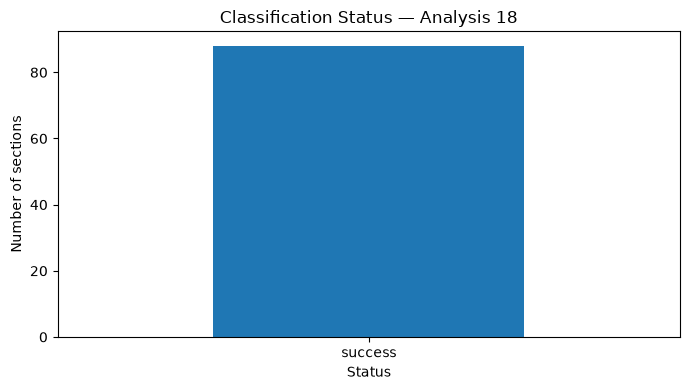

In [7]:
status_counts = results_df["status"].fillna("Missing status").value_counts()
ax = status_counts.plot(kind="bar", figsize=(7, 4))
ax.set_title(f"Classification Status — Analysis {ANALYSIS_ID}")
ax.set_xlabel("Status")
ax.set_ylabel("Number of sections")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 5. Sentiment distribution

Only successful classifications are included.

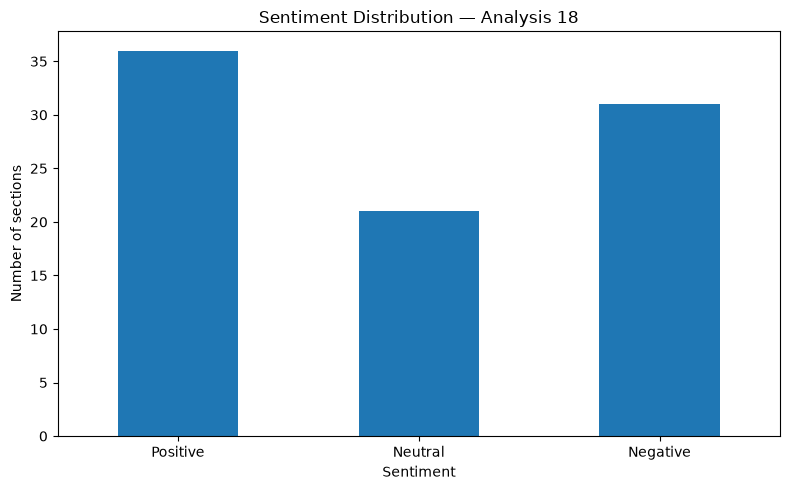

,count
sentiment,
Positive,36
Neutral,21
Negative,31


In [5]:
sentiment_order = ["Positive", "Neutral", "Negative"]
sentiment_counts = successful["sentiment"].value_counts().reindex(sentiment_order, fill_value=0)

ax = sentiment_counts.plot(kind="bar", figsize=(8, 5))
ax.set_title(f"Sentiment Distribution — Analysis {ANALYSIS_ID}")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of sections")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

display(sentiment_counts.rename("count").to_frame())

## 6. Tone distribution

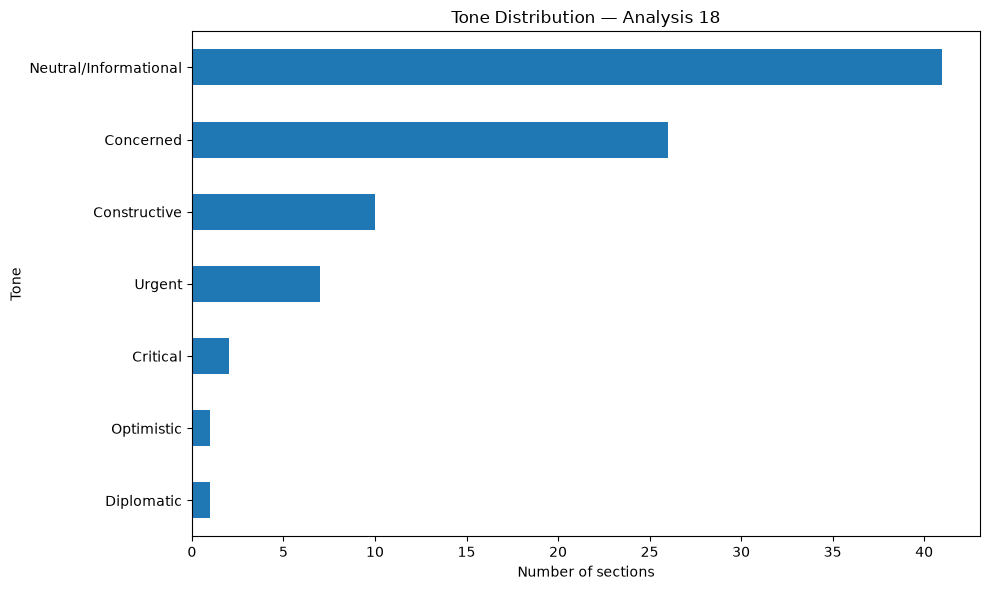

,count
tone,
Neutral/Informational,41
Concerned,26
Constructive,10
Urgent,7
Critical,2
Optimistic,1
Diplomatic,1


In [ ]:
tone_order = [
    "Diplomatic",
    "Concerned",
    "Critical",
    "Urgent",
    "Optimistic",
    "Neutral/Informational",
    "Constructive",
]
tone_counts = successful["tone"].value_counts().reindex(tone_order, fill_value=0).sort_values()

ax = tone_counts.plot(kind="barh", figsize=(10, 6))
ax.set_title(f"Tone Distribution — Analysis {ANALYSIS_ID}")
ax.set_xlabel("Number of sections")
ax.set_ylabel("Tone")
plt.tight_layout()
plt.show()

display(tone_counts.sort_values(ascending=False).rename("count").to_frame())

## 7. Sentiment and tone relationship

A crosstab and stacked bar chart show which tones occur with each sentiment.

tone,Concerned,Constructive,Critical,Diplomatic,Neutral/Informational,Optimistic,Urgent
sentiment,,,,,,,
Positive,0,10,0,1,22,1,2
Neutral,3,0,0,0,18,0,0
Negative,23,0,2,0,1,0,5


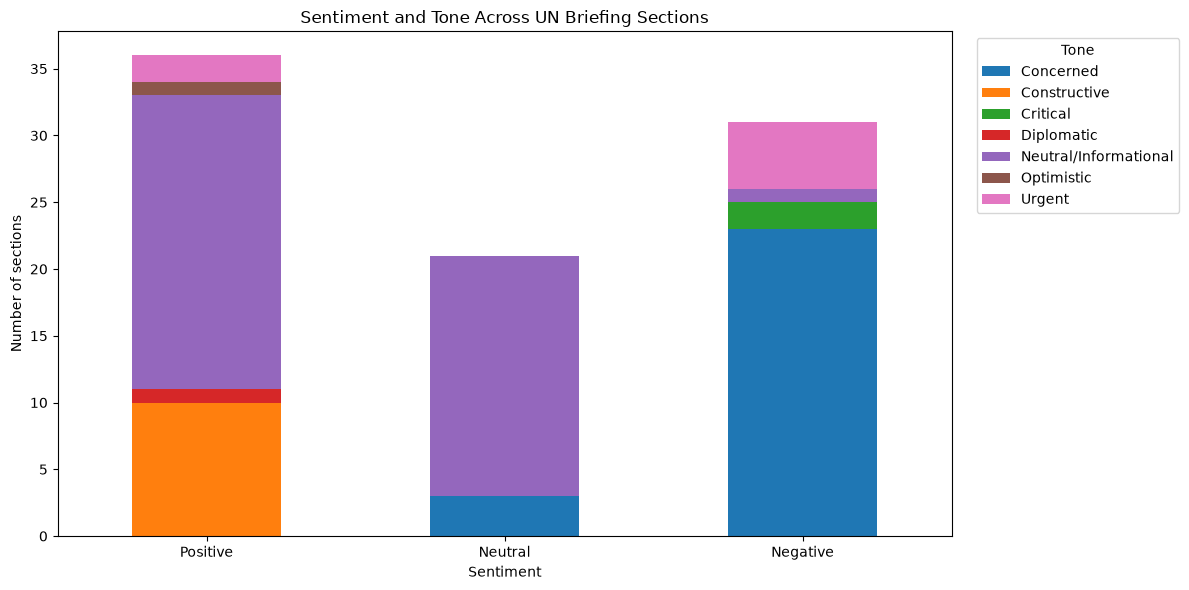

In [10]:
cross_tab = pd.crosstab(successful["sentiment"], successful["tone"])
cross_tab = cross_tab.reindex(index=sentiment_order, fill_value=0)
display(cross_tab)

ax = cross_tab.plot(kind="bar", stacked=True, figsize=(12, 6))
ax.set_title("Sentiment and Tone Across UN Briefing Sections")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of sections")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Tone", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 8.Sentiment over time — last 6 months


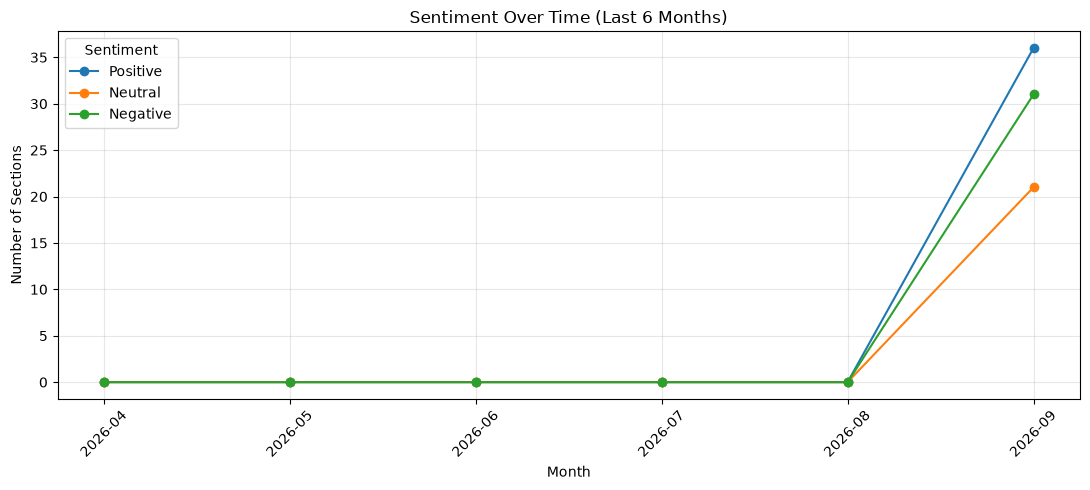

In [ ]:
import matplotlib.pyplot as plt

sentiment_order = ["Positive", "Neutral", "Negative"]

sentiment_monthly = (
    last_6_months.groupby([last_6_months["briefing_date"].dt.to_period("M"), "sentiment"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=sentiment_order, fill_value=0)
)

# Ensure all six months appear, including months with no records
# Determine the six-month period from the latest available briefing date.
#For example, if the latest valid briefing date is 18 September 2026, 
#the DataFrame includes records from April 1 through September 30, 2026—six calendar months.
months = pd.period_range(
    start=last_6_months["briefing_date"].max().to_period("M") - 5,
    end=last_6_months["briefing_date"].max().to_period("M"),
    freq="M",
)
#chart cell can then use last_6_months to count Positive, Neutral, and Negative sections per month.
sentiment_monthly = sentiment_monthly.reindex(months, fill_value=0)
sentiment_monthly.index = sentiment_monthly.index.astype(str)

ax = sentiment_monthly.plot(
    kind="line",
    marker="o",
    figsize=(11, 5),
)

ax.set_title("Sentiment Over Time (Last 6 Months)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Sections")
ax.legend(title="Sentiment")
ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 9.Sentiment over time — last 6 months

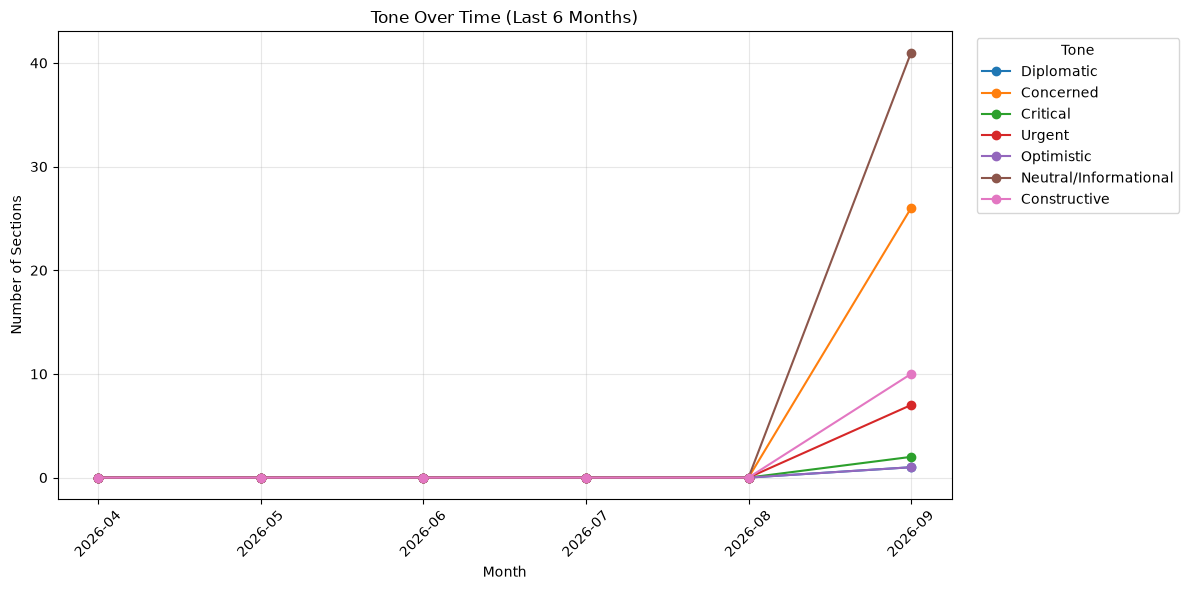

In [ ]:
tone_order = [
    "Diplomatic",
    "Concerned",
    "Critical",
    "Urgent",
    "Optimistic",
    "Neutral/Informational",
    "Constructive",
]

tone_monthly = (
    last_6_months.groupby([last_6_months["briefing_date"].dt.to_period("M"), "tone"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=tone_order, fill_value=0)
)

tone_monthly = tone_monthly.reindex(months, fill_value=0)
tone_monthly.index = tone_monthly.index.astype(str)

ax = tone_monthly.plot(
    kind="line",
    marker="o",
    figsize=(12, 6),
)

ax.set_title("Tone Over Time (Last 6 Months)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Sections")
ax.legend(title="Tone", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Observations

Positive sentiment: Most sections have a Neutral/Informational tone. Some sections have a Constructive tone.

Neutral sentiment: Most sections also have a Neutral/Informational tone.

Negative sentiment: Most sections have a Concerned tone. A few sections have an Urgent or Critical tone.

Overall, Neutral/Informational is the most common tone for positive and neutral sections, while Concerned is the most common tone for negative sections.

This analysis helps us understand how the UN communicates about different issues in its daily briefings.